# ANOVA de Marketing
Dos ANOVA: Leads según Canal (Oneway) y Presupuesto según Canal × Año (multifactorial)

In [1]:
%pip install -q pandas numpy matplotlib seaborn scipy statsmodels ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.formula.api import ols
from scipy import stats
from statsmodels.graphics.factorplots import interaction_plot
from IPython.display import display
import ipywidgets as widgets
from pathlib import Path

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False})
ALFA = 0.05


## 1. Carga y preparación

In [3]:
archivo = Path("Analisis GAC Full7agosto 2026(Marketing).csv")
base = pd.read_csv(archivo, header=None, dtype=str, encoding="utf-8-sig")

def texto(x):
    return "" if pd.isna(x) else str(x).strip()

def numero(x):
    s = texto(x).replace("$", "").replace(",", "").replace(" ", "")
    if s in ("", "-", "—"):
        return np.nan
    return pd.to_numeric(s, errors="coerce")

# Identificamos el encabezado del bloque y sus fechas originales.
inicio = base.index[base[0].fillna("").str.strip().eq("Presupuesto mensual de MKT por canal")][0]
encabezado = base.loc[inicio + 1]
meses = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4,
         "mayo": 5, "junio": 6, "julio": 7, "agosto": 8,
         "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}
columnas_fecha = {}
for col, valor in encabezado.items():
    partes = texto(valor).lower().split(",")
    if len(partes) == 2 and partes[0].strip() in meses:
        anio = int(partes[1].strip())
        anio = anio + 2000 if anio < 100 else anio
        columnas_fecha[col] = pd.Timestamp(anio, meses[partes[0].strip()], 1)

registros = []
for canal in ["Plaza", "Digital", "Piso"]:
    candidatos = base.index[(base.index > inicio) & base[0].fillna("").str.strip().eq(canal)]
    fila = candidatos[0]
    assert texto(base.loc[fila + 1, 0]) == "Leads"
    assert texto(base.loc[fila + 2, 0]) == "Ventas"
    for col, fecha in columnas_fecha.items():
        registros.append({"Canal": canal, "Fecha": fecha,
                          "Leads": numero(base.loc[fila + 1, col]),
                          "Ventas": numero(base.loc[fila + 2, col]),
                          "Presupuesto": numero(base.loc[fila, col])})

datos = pd.DataFrame(registros)
datos["Anio"] = datos["Fecha"].dt.year.astype(str)
datos["Mes"] = datos["Fecha"].dt.month
objetivos = ["Leads", "Ventas", "Presupuesto"]
print("Nulos en el bloque original:")
display(datos[objetivos].isna().sum().to_frame("Nulos"))

# Periodo común: solo fechas con los tres indicadores en los tres canales.
completos = datos.dropna(subset=objetivos)
fechas_completas = completos.groupby("Fecha")["Canal"].nunique()
fechas_completas = fechas_completas[fechas_completas.eq(3)].index
df = completos[completos["Fecha"].isin(fechas_completas)].copy()
df = df.sort_values(["Fecha", "Canal"]).reset_index(drop=True)
assert not df.duplicated(["Canal", "Fecha"]).any()
assert (df[objetivos] >= 0).all().all()
print("Periodo:", df.Fecha.min().date(), "a", df.Fecha.max().date())
print("Observaciones:", len(df))
display(df.head(9))
df.info()
display(pd.crosstab(df["Canal"], df["Anio"]))


Nulos en el bloque original:


,Nulos
Leads,0
Ventas,4
Presupuesto,45


Periodo: 2025-04-01 a 2026-05-01
Observaciones: 42


,Canal,Fecha,Leads,Ventas,Presupuesto,Anio,Mes
0,Digital,2025-04-01,749,5.0,62037.00,2025,4
1,Piso,2025-04-01,43,13.0,273068.00,2025,4
2,Plaza,2025-04-01,301,8.0,182000.00,2025,4
3,Digital,2025-05-01,361,9.0,107263.00,2025,5
4,Piso,2025-05-01,65,12.0,281540.67,2025,5
5,Plaza,2025-05-01,275,5.0,182000.00,2025,5
6,Digital,2025-06-01,576,12.0,122616.00,2025,6
7,Piso,2025-06-01,59,10.0,73763.00,2025,6
8,Plaza,2025-06-01,355,13.0,592000.00,2025,6


<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Canal        42 non-null     str           
 1   Fecha        42 non-null     datetime64[us]
 2   Leads        42 non-null     int64         
 3   Ventas       42 non-null     float64       
 4   Presupuesto  42 non-null     float64       
 5   Anio         42 non-null     str           
 6   Mes          42 non-null     int32         
dtypes: datetime64[us](1), float64(2), int32(1), int64(1), str(2)
memory usage: 2.7 KB


Anio,2025,2026
Canal,,
Digital,9,5
Piso,9,5
Plaza,9,5


## 2. Exploración y valores atípicos

In [4]:
display(df.groupby("Canal")[objetivos].agg(["count", "mean", "std", "min", "max"]).round(2))
atipicos = []
for canal, grupo in df.groupby("Canal"):
    for variable in objetivos:
        q1, q3 = grupo[variable].quantile([0.25, 0.75])
        iqr = q3 - q1
        mascara = (grupo[variable] < q1 - 1.5 * iqr) | (grupo[variable] > q3 + 1.5 * iqr)
        for _, fila in grupo.loc[mascara].iterrows():
            atipicos.append({"Canal": canal, "Fecha": fila.Fecha,
                             "Variable": variable, "Valor": fila[variable]})
display(pd.DataFrame(atipicos, columns=["Canal", "Fecha", "Variable", "Valor"]))


Leads                           Ventas                         \
        count    mean     std  min  max  count  mean   std  min   max   
Canal                                                                   
Digital    14  719.71  166.33  361  980     14  9.86  2.88  5.0  15.0   
Piso       14   77.00   19.96   43  115     14  8.86  2.07  6.0  13.0   
Plaza      14  348.71   63.26  274  492     14  9.07  3.32  5.0  15.0   

        Presupuesto                                            
              count       mean        std       min       max  
Canal                                                          
Digital          14  110002.79   20440.26   62037.0  143000.0  
Piso             14  493851.31  245615.46   73763.0  939309.0  
Plaza            14  263438.14  126350.57  182000.0  592000.0

,Canal,Fecha,Variable,Valor
0,Digital,2025-04-01,Presupuesto,62037.0
1,Plaza,2025-06-01,Presupuesto,592000.0
2,Plaza,2026-01-01,Presupuesto,476334.0


## 3. ANOVA Oneway · Leads según Canal

In [5]:
grupos_leads = [grupo["Leads"].to_numpy() for _, grupo in df.groupby("Canal")]
anova_leads = stats.f_oneway(*grupos_leads)
print(f"Leads · F = {anova_leads.statistic:.6f} | p-value = {anova_leads.pvalue:.6g}")
modelo_leads = ols("Leads ~ C(Canal)", data=df).fit()
tabla_leads = sm.stats.anova_lm(modelo_leads, typ=2)
display(tabla_leads)


Leads · F = 136.346033 | p-value = 2.50097e-18


,sum_sq,df,F,PR(>F)
C(Canal),2.914573e+06,2.0,136.346033,2.500966e-18
Residual,4.168377e+05,39.0,NaN,NaN


## 4. Ventas: análisis descriptivo

In [6]:
# Ventas se utiliza solamente de forma descriptiva.
display(df.groupby("Canal")["Ventas"].agg(["count", "mean", "std", "min", "max"]).round(2))

,count,mean,std,min,max
Canal,,,,,
Digital,14,9.86,2.88,5.0,15.0
Piso,14,8.86,2.07,6.0,13.0
Plaza,14,9.07,3.32,5.0,15.0


## 5. ANOVA multifactorial · Presupuesto según Canal y Año

In [7]:
modelo_presupuesto = ols(
    "Presupuesto ~ C(Canal, Sum) * C(Anio, Sum)", data=df
).fit()
tabla_presupuesto = sm.stats.anova_lm(modelo_presupuesto, typ=3)
display(tabla_presupuesto)
for termino, fila in tabla_presupuesto.iterrows():
    if termino not in ["Intercept", "Residual"]:
        print(f"{termino} · F = {fila['F']:.6f} | p-value = {fila['PR(>F)']:.6g}")


,sum_sq,df,F,PR(>F)
Intercept,3.297160e+12,1.0,120.325709,4.956199e-13
"C(Canal, Sum)",9.327703e+11,2.0,17.020142,6.268778e-06
"C(Anio, Sum)",5.069396e+09,1.0,0.185001,6.696739e-01
"C(Canal, Sum):C(Anio, Sum)",5.680146e+09,2.0,0.103645,9.018134e-01
Residual,9.864704e+11,36.0,NaN,NaN


C(Canal, Sum) · F = 17.020142 | p-value = 6.26878e-06
C(Anio, Sum) · F = 0.185001 | p-value = 0.669674
C(Canal, Sum):C(Anio, Sum) · F = 0.103645 | p-value = 0.901813


## 6. Gráficas
Boxplots, medias con intervalos de confianza descriptivos del 95%, heatmaps e interacción. Cada gráfico conserva las unidades de su variable.

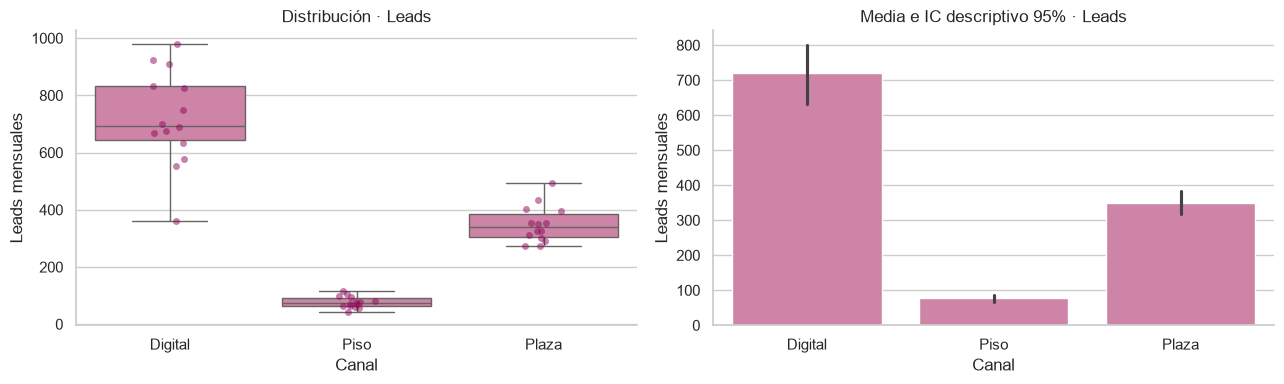

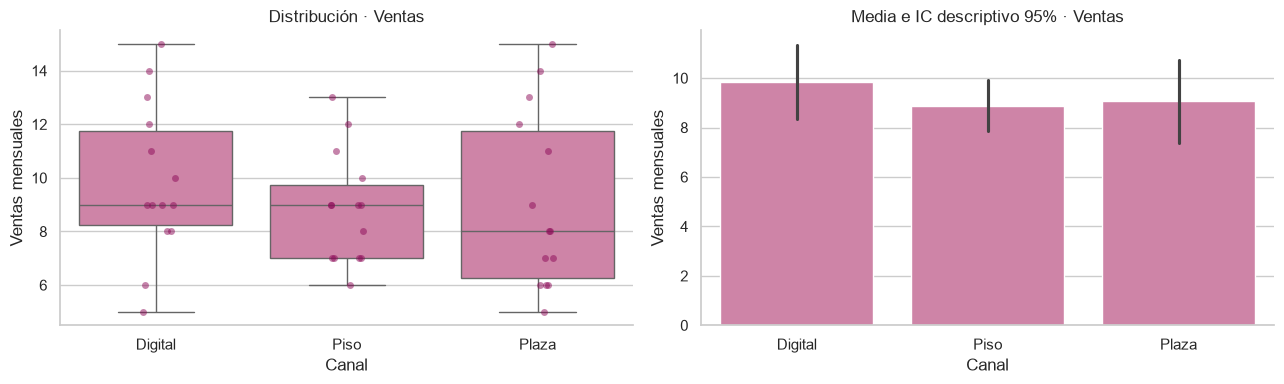

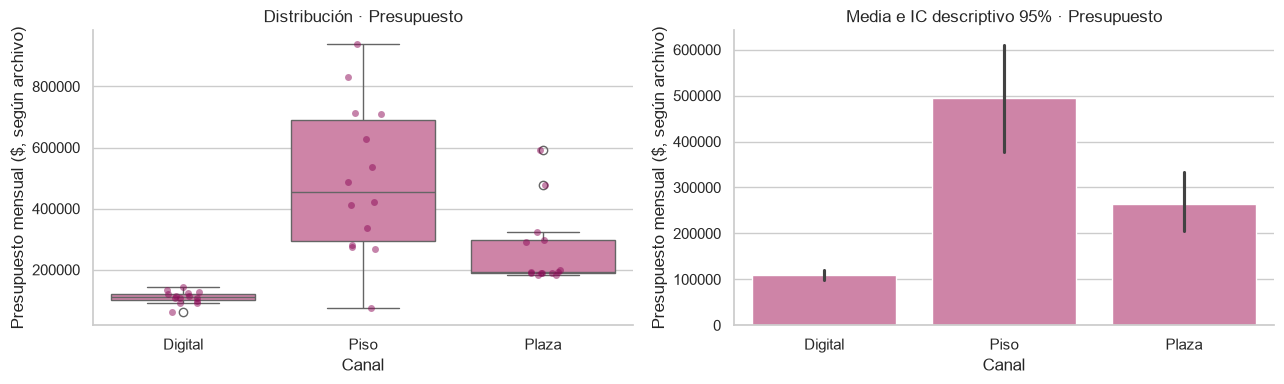

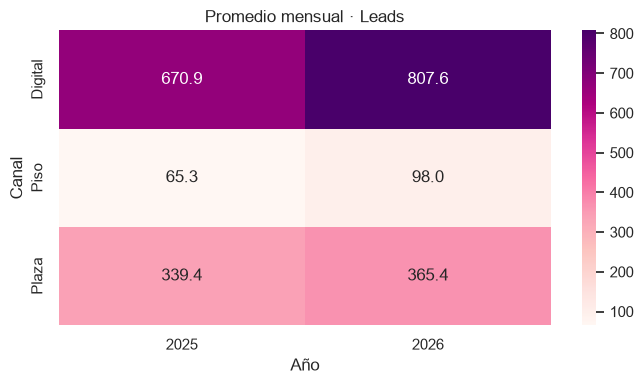

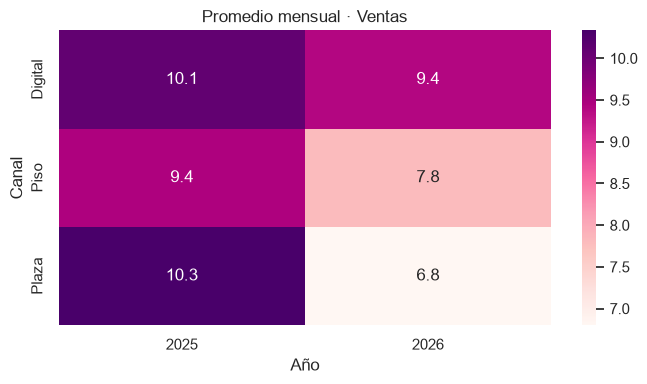

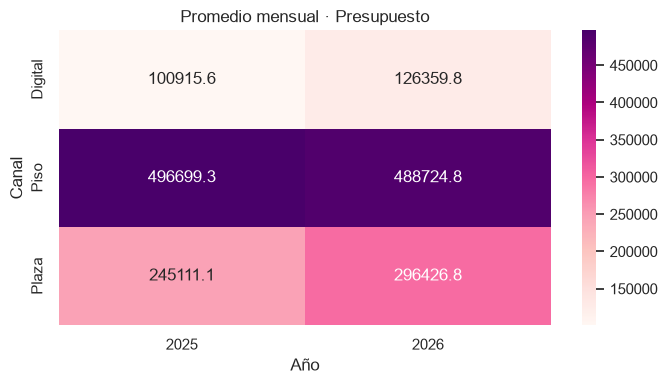

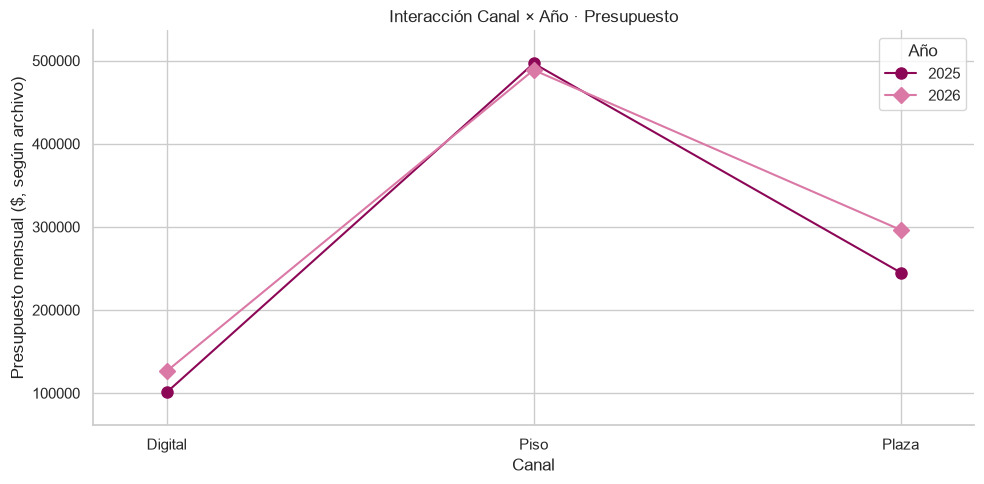

In [13]:
unidades = {
    "Leads": "Leads mensuales",
    "Ventas": "Ventas mensuales",
    "Presupuesto": "Presupuesto mensual ($, según archivo)"
}

for variable in objetivos:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    sns.boxplot(
        data=df, x="Canal", y=variable,
        color="#da78a6", ax=axes[0]
    )

    sns.stripplot(
        data=df, x="Canal", y=variable,
        color="#8c0857", alpha=0.5, ax=axes[0]
    )

    sns.barplot(
        data=df, x="Canal", y=variable,
        color="#da78a6", errorbar=("ci", 95),
        seed=42, ax=axes[1]
    )

    axes[0].set_title(f"Distribución · {variable}")
    axes[1].set_title(f"Media e IC descriptivo 95% · {variable}")

    for ax in axes:
        ax.set_ylabel(unidades[variable])

    plt.tight_layout()
    plt.show()

for variable in objetivos:
    matriz = df.pivot_table(
        index="Canal", columns="Anio",
        values=variable, aggfunc="mean"
    )

    plt.figure(figsize=(7, 4))
    sns.heatmap(
        matriz, annot=True, fmt=".1f", cmap="RdPu"
    )
    plt.title(f"Promedio mensual · {variable}")
    plt.xlabel("Año")
    plt.tight_layout()
    plt.show()

fig = interaction_plot(
    df["Canal"], df["Anio"], df["Presupuesto"],
    colors=["#8c0857", "#da78a6"],
    markers=["o", "D"], ms=8
)

fig.set_size_inches(10, 5)
plt.title("Interacción Canal × Año · Presupuesto")
plt.ylabel(unidades["Presupuesto"])
plt.legend(title="Año")
plt.tight_layout()
plt.show()

## 7. Tabla de métricas y comprobación de supuestos

In [14]:
resumen = []
for nombre, variable, tabla in [("Oneway", "Leads", tabla_leads),
                                ("Factorial", "Presupuesto", tabla_presupuesto)]:
    for termino, fila in tabla.iterrows():
        if termino in ["Intercept", "Residual"]:
            continue
        resumen.append({"Analisis": nombre, "Objetivo": variable, "Termino": termino,
                        "F": fila["F"], "p-value": fila["PR(>F)"], "Alfa": ALFA})
metricas = pd.DataFrame(resumen)
display(metricas)

supuestos = []
for variable, modelo in [("Leads", modelo_leads), ("Presupuesto", modelo_presupuesto)]:
    claves = ["Canal", "Anio"] if variable == "Presupuesto" else ["Canal"]
    grupos = [g[variable].values for _, g in df.groupby(claves)]
    shapiro = stats.shapiro(modelo.resid)
    levene = stats.levene(*grupos, center="median")
    supuestos.append({"Objetivo": variable, "Shapiro p-value": shapiro.pvalue,
                      "Levene p-value": levene.pvalue})
display(pd.DataFrame(supuestos))


,Analisis,Objetivo,Termino,F,p-value,Alfa
0,Oneway,Leads,C(Canal),136.346033,2.500966e-18,0.05
1,Factorial,Presupuesto,"C(Canal, Sum)",17.020142,6.268778e-06,0.05
2,Factorial,Presupuesto,"C(Anio, Sum)",0.185001,6.696739e-01,0.05
3,Factorial,Presupuesto,"C(Canal, Sum):C(Anio, Sum)",0.103645,9.018134e-01,0.05


,Objetivo,Shapiro p-value,Levene p-value
0,Leads,0.001288,0.000255
1,Presupuesto,0.001316,0.001874


## 8. Selector adicional de gráficos
Este widget explora gráficas y tablas; no recalcula los modelos ni modifica su muestra. Los gráficos anteriores funcionan aunque el entorno no muestre widgets.

In [16]:
def explorar(variable, grafico):
    if grafico == "Tabla":
        display(
            df.groupby(["Canal", "Anio"])[variable]
            .agg(["count", "mean", "std"]).round(2)
        )
        return

    plt.figure(figsize=(9, 4))

    if grafico == "Boxplot":
        sns.boxplot(
            data=df, x="Canal", y=variable, hue="Anio",
            palette=["#8c0857", "#da78a6"]
        )

    elif grafico == "Heatmap":
        sns.heatmap(
            df.pivot_table(
                index="Canal", columns="Anio", values=variable
            ),
            annot=True, fmt=".1f", cmap="RdPu"
        )

    else:
        sns.lineplot(
            data=df, x="Fecha", y=variable,
            hue="Canal", marker="o",
            palette={
                "Digital": "#8c0857",
                "Piso": "#da78a6",
                "Plaza": "#efb6cd"
            }
        )
        plt.xticks(rotation=30)

    plt.title(f"{grafico} · {variable}")
    plt.tight_layout()
    plt.show()


widgets.interact(
    explorar,
    variable=widgets.Dropdown(
        options=objetivos, description="Objetivo:"
    ),
    grafico=widgets.Dropdown(
        options=["Boxplot", "Heatmap", "Serie mensual", "Tabla"],
        description="Vista:"
    )
)

interactive(children=(Dropdown(description='Objetivo:', options=('Leads', 'Ventas', 'Presupuesto'), value='Lea…

<function __main__.explorar(variable, grafico)>